In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/Matches.csv')

# Display basic information about the dataset
print("Dataset Shape:", df.shape)
print("\nDataset Columns & Info:")
df.info()

# Show the first few rows
display(df.head())

/tmp/ipykernel_2100/960046141.py:4: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/Matches.csv')


Dataset Shape: (238858, 48)

Dataset Columns & Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 238858 entries, 0 to 238857
Data columns (total 48 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Division     238858 non-null  object 
 1   MatchDate    238858 non-null  object 
 2   MatchTime    107373 non-null  object 
 3   HomeTeam     238858 non-null  object 
 4   AwayTeam     238858 non-null  object 
 5   HomeElo      149898 non-null  float64
 6   AwayElo      149829 non-null  float64
 7   Form3Home    237334 non-null  float64
 8   Form5Home    237323 non-null  float64
 9   Form3Away    237335 non-null  float64
 10  Form5Away    237324 non-null  float64
 11  FTHome       238854 non-null  float64
 12  FTAway       238854 non-null  float64
 13  FTResult     238854 non-null  object 
 14  HTHome       184278 non-null  float64
 15  HTAway       184278 non-null  float64
 16  HTResult     184278 non-null  object 
 17  HomeShots    1

,Division,MatchDate,MatchTime,HomeTeam,AwayTeam,HomeElo,AwayElo,Form3Home,Form5Home,Form3Away,...,MaxUnder25,HandiSize,HandiHome,HandiAway,C_LTH,C_LTA,C_VHD,C_VAD,C_HTB,C_PHB
0,F1,2000-07-28,NaN,Marseille,Troyes,1686.34,1586.57,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,F1,2000-07-28,NaN,Paris SG,Strasbourg,1714.89,1642.51,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,F2,2000-07-28,NaN,Wasquehal,Nancy,1465.08,1633.80,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,F1,2000-07-29,NaN,Auxerre,Sedan,1635.58,1624.22,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,F1,2000-07-29,NaN,Bordeaux,Metz,1734.34,1673.11,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
# Check for missing values in each column
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values[missing_values > 0])

# Check for duplicate rows
duplicates = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicates}")

Missing values per column:
MatchTime      131485
HomeElo         88960
AwayElo         89029
Form3Home        1524
Form5Home        1535
Form3Away        1523
Form5Away        1534
FTHome              4
FTAway              4
FTResult            4
HTHome          54580
HTAway          54580
HTResult        54580
HomeShots      116375
AwayShots      116372
HomeTarget     117181
AwayTarget     117178
HomeFouls      117137
AwayFouls      117137
HomeCorners    116747
AwayCorners    116747
HomeYellow     111260
AwayYellow     111259
HomeRed        111259
AwayRed        111261
OddHome          3042
OddDraw          3042
OddAway          3042
MaxHome         27647
MaxDraw         27647
MaxAway         27647
Over25          82171
Under25         82172
MaxOver25       82171
MaxUnder25      82172
HandiSize       73846
HandiHome       74107
HandiAway       74131
C_LTH          126256
C_LTA          126256
C_VHD          126256
C_VAD          126256
C_HTB          126256
C_PHB          126256
dtype

In [3]:
# 1. Remove completely blank rows (rows where all columns are NaN)
clean_df = df.dropna(how='all').copy()

# 2. Drop rows where key target variables (FTResult, FTHome, FTAway) are missing
clean_df = clean_df.dropna(subset=['FTResult', 'FTHome', 'FTAway'])

# 3. Standardize MatchDate column to datetime format
clean_df['MatchDate'] = pd.to_datetime(clean_df['MatchDate'], errors='coerce')

# 4. Standardize MatchTime column to string and fill NaNs gracefully to resolve mixed-type warnings
clean_df['MatchTime'] = clean_df['MatchTime'].astype(str).str.strip().replace({'nan': None, '': None})

# 5. Review shape and basic info of the cleaned dataset
print("Cleaned Dataset Shape:", clean_df.shape)
print("\nRemaining missing values in core columns:")
print(clean_df[['Division', 'MatchDate', 'HomeTeam', 'AwayTeam', 'FTHome', 'FTAway', 'FTResult']].isnull().sum())

# Save the cleaned dataset to a new CSV file
clean_df.to_csv('/content/Matches_Cleaned.csv', index=False)
print("\nCleaned dataset successfully saved to '/content/Matches_Cleaned.csv'")

Cleaned Dataset Shape: (238854, 48)

Remaining missing values in core columns:
Division     0
MatchDate    0
HomeTeam     0
AwayTeam     0
FTHome       0
FTAway       0
FTResult     0
dtype: int64

Cleaned dataset successfully saved to '/content/Matches_Cleaned.csv'


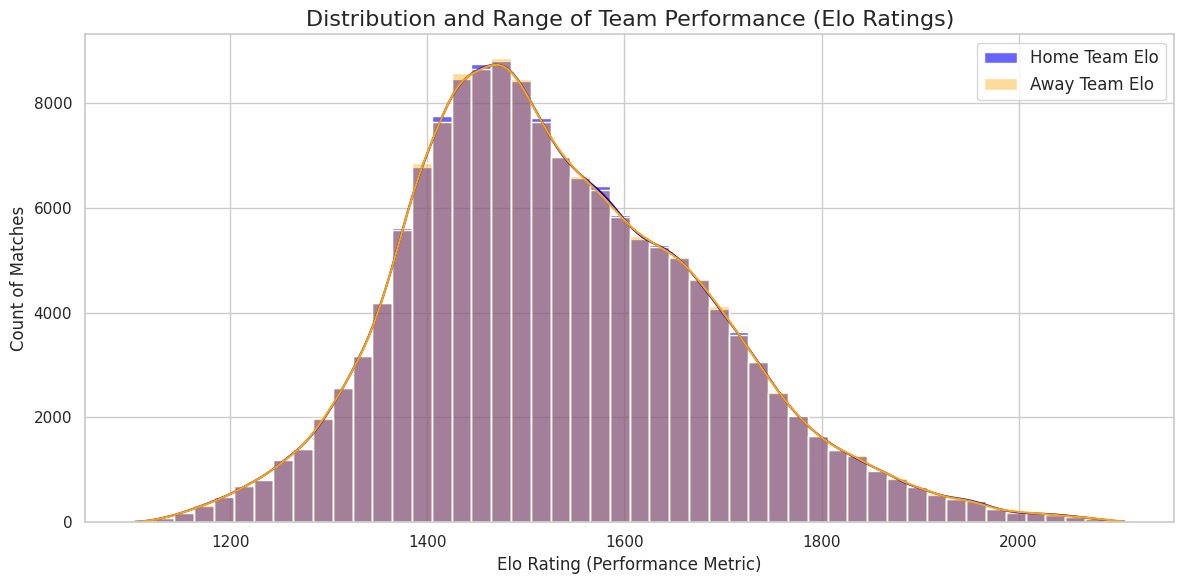

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visualization style
sns.set_theme(style="whitegrid")

# Create a figure to plot Elo rating distribution
plt.figure(figsize=(12, 6))

# Plot Home Elo ratings distribution
sns.histplot(clean_df['HomeElo'].dropna(), kde=True, color='blue', label='Home Team Elo', bins=50, alpha=0.6)

# Plot Away Elo ratings distribution
sns.histplot(clean_df['AwayElo'].dropna(), kde=True, color='orange', label='Away Team Elo', bins=50, alpha=0.4)

plt.title('Distribution and Range of Team Performance (Elo Ratings)', fontsize=16)
plt.xlabel('Elo Rating (Performance Metric)', fontsize=12)
plt.ylabel('Count of Matches', fontsize=12)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

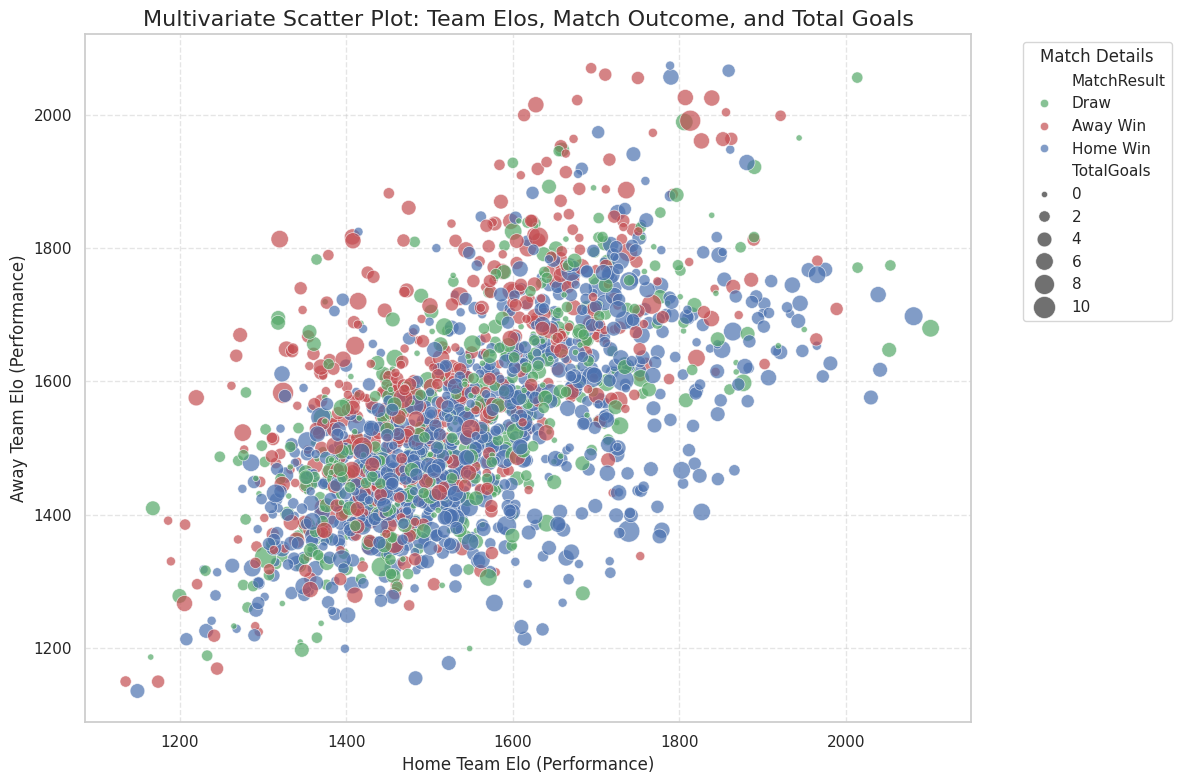

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Prepare multivariate data from clean_df
# Drop rows where Elo ratings are missing for visualization
plot_data = clean_df.dropna(subset=['HomeElo', 'AwayElo', 'FTHome', 'FTAway', 'FTResult']).copy()

# 1. Add Total Goals (FTHome + FTAway) for sizing
plot_data['TotalGoals'] = plot_data['FTHome'] + plot_data['FTAway']

# To make sure the plot remains responsive, we will take a representative sample of 2,000 matches
sample_data = plot_data.sample(n=min(2000, len(plot_data)), random_state=42)

# Map results to clear labels
result_map = {'H': 'Home Win', 'A': 'Away Win', 'D': 'Draw'}
sample_data['MatchResult'] = sample_data['FTResult'].map(result_map)

# Create multivariate scatter plot
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=sample_data,
    x='HomeElo',
    y='AwayElo',
    hue='MatchResult',
    size='TotalGoals',
    sizes=(20, 250),
    alpha=0.7,
    palette={'Home Win': '#4C72B0', 'Away Win': '#C44E52', 'Draw': '#55A868'}
)

plt.title('Multivariate Scatter Plot: Team Elos, Match Outcome, and Total Goals', fontsize=16)
plt.xlabel('Home Team Elo (Performance)', fontsize=12)
plt.ylabel('Away Team Elo (Performance)', fontsize=12)
plt.legend(title='Match Details', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

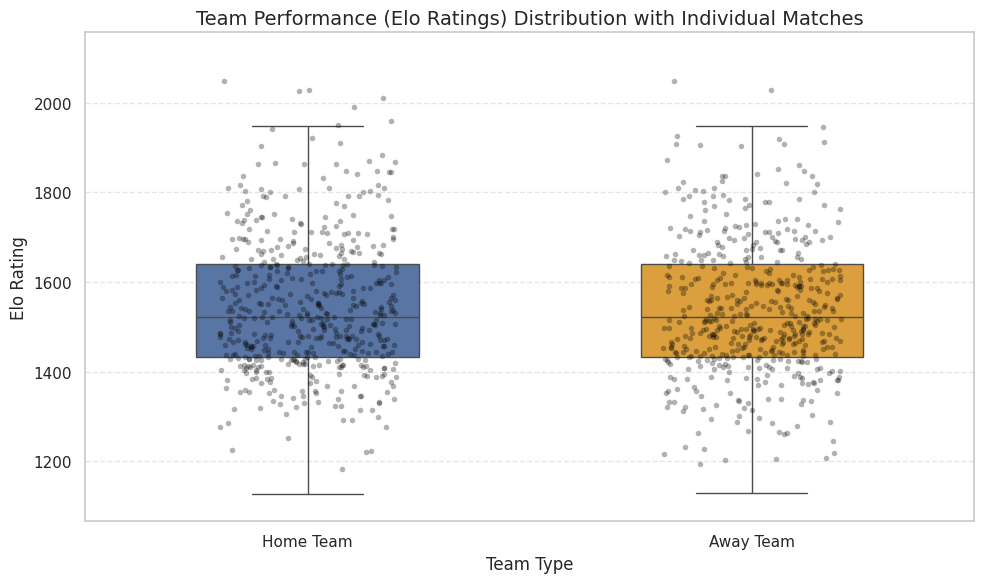

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare the data by melting HomeElo and AwayElo into a long format for plotting
elo_df = clean_df[['HomeElo', 'AwayElo']].dropna().copy()
elo_long = elo_df.melt(value_vars=['HomeElo', 'AwayElo'], var_name='TeamType', value_name='EloRating')

# Map to user-friendly labels
elo_long['TeamType'] = elo_long['TeamType'].map({'HomeElo': 'Home Team', 'AwayElo': 'Away Team'})

# Take a sample for the overlay points to keep the visualization clean and fast
sample_points = elo_long.sample(n=min(1000, len(elo_long)), random_state=42)

plt.figure(figsize=(10, 6))

# 1. Draw the boxplot (with hue assigned and legend disabled to avoid FutureWarnings)
sns.boxplot(
    data=elo_long,
    x='TeamType',
    y='EloRating',
    hue='TeamType',
    legend=False,
    palette={'Home Team': '#4C72B0', 'Away Team': '#F5A623'},
    width=0.5,
    fliersize=0 # Hide default outliers to avoid duplicate plotting with stripplot
)

# 2. Overlay individual data points (jittered strip plot)
sns.stripplot(
    data=sample_points,
    x='TeamType',
    y='EloRating',
    color='black',
    alpha=0.3,
    size=4,
    jitter=0.2
)

plt.title('Team Performance (Elo Ratings) Distribution with Individual Matches', fontsize=14)
plt.xlabel('Team Type', fontsize=12)
plt.ylabel('Elo Rating', fontsize=12)
plt.grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

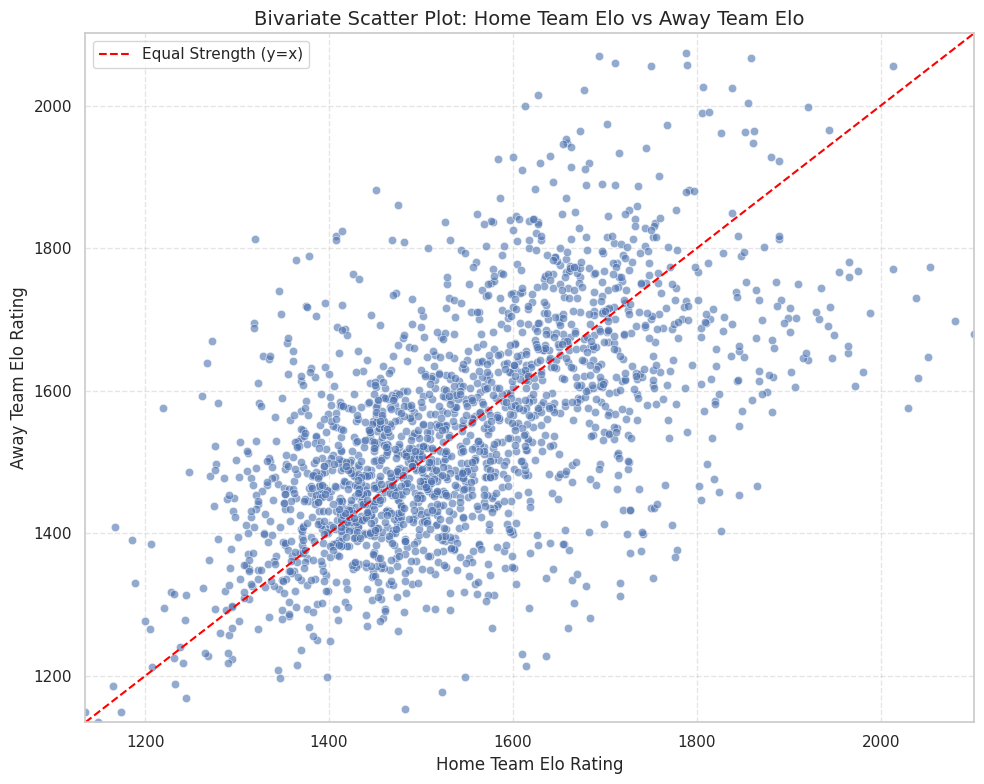

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Drop rows where Elo ratings are missing
elo_matchups = clean_df[['HomeElo', 'AwayElo']].dropna().copy()

# Sample 2,000 matches to keep the plot highly responsive and clean
sample_matchups = elo_matchups.sample(n=min(2000, len(elo_matchups)), random_state=42)

plt.figure(figsize=(10, 8))

# Create scatter plot
sns.scatterplot(
    data=sample_matchups,
    x='HomeElo',
    y='AwayElo',
    color='#4C72B0',
    alpha=0.6,
    edgecolor='w',
    linewidth=0.5
)

# Add a diagonal line (y = x) representing perfectly matched opponents
lims = [
    min(sample_matchups['HomeElo'].min(), sample_matchups['AwayElo'].min()),
    max(sample_matchups['HomeElo'].max(), sample_matchups['AwayElo'].max())
]
plt.plot(lims, lims, color='red', linestyle='--', linewidth=1.5, label='Equal Strength (y=x)')

plt.title('Bivariate Scatter Plot: Home Team Elo vs Away Team Elo', fontsize=14)
plt.xlabel('Home Team Elo Rating', fontsize=12)
plt.ylabel('Away Team Elo Rating', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

plt.xlim(lims)
plt.ylim(lims)
plt.tight_layout()
plt.show()

In [13]:
import ipywidgets as widgets
from ipywidgets import interact
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Prepare dataset for dropdown interactions
interactive_df = clean_df.dropna(subset=['HomeElo', 'AwayElo', 'Division', 'FTResult']).copy()

# Get unique sorted list of divisions
divisions = ['All'] + sorted(interactive_df['Division'].unique().tolist())

@interact(Division=widgets.Dropdown(options=divisions, value='All', description='Division:'))
def update_scatter(Division):
    plt.figure(figsize=(10, 8))

    # Filter data based on selected division
    if Division == 'All':
        subset = interactive_df
    else:
        subset = interactive_df[interactive_df['Division'] == Division]

    # Take a manageable sample size for fluid performance
    sample_size = min(1500, len(subset))
    plot_subset = subset.sample(n=sample_size, random_state=42) if sample_size > 0 else subset

    if len(plot_subset) == 0:
        plt.text(0.5, 0.5, 'No Data Available for Selection', ha='center', va='center', fontsize=14)
        plt.show()
        return

    sns.scatterplot(
        data=plot_subset,
        x='HomeElo',
        y='AwayElo',
        hue='FTResult',
        palette={'H': '#4C72B0', 'A': '#C44E52', 'D': '#55A868'},
        alpha=0.7,
        edgecolor='w'
    )

    # Add identical reference limits line
    lims = [1100, 2150]
    plt.plot(lims, lims, color='gray', linestyle='--', linewidth=1.5, label='Equal Strength')

    plt.title(f'Interactive Scatter Plot: Home vs Away Elo (Division: {Division})', fontsize=14)
    plt.xlabel('Home Team Elo Rating', fontsize=12)
    plt.ylabel('Away Team Elo Rating', fontsize=12)
    plt.xlim(lims)
    plt.ylim(lims)
    plt.legend(title='Outcome (H: Home Win, A: Away Win, D: Draw)', loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

interactive(children=(Dropdown(description='Division:', options=('All', 'AUT', 'B1', 'D1', 'D2', 'DEN', 'E0', …

In [16]:
import plotly.express as px
import pandas as pd

# Prepare data with a 'Year' column for temporal animation
temporal_data = clean_df.dropna(subset=['HomeElo', 'AwayElo', 'MatchDate', 'FTResult']).copy()
temporal_data['Year'] = temporal_data['MatchDate'].dt.year

# Sort chronologically to make sure the animation slider moves sequentially
temporal_data = temporal_data.sort_values('Year')

# Sample data per year to ensure smooth animation and responsive rendering
sampled_temporal = temporal_data.groupby('Year', group_keys=False).apply(
    lambda x: x.sample(n=min(150, len(x)), random_state=42)
)

# Map FTResult for user-friendly labeling
result_map = {'H': 'Home Win', 'A': 'Away Win', 'D': 'Draw'}
sampled_temporal['MatchResult'] = sampled_temporal['FTResult'].map(result_map)

# Create the animated scatter plot using Plotly Express
fig = px.scatter(
    sampled_temporal,
    x='HomeElo',
    y='AwayElo',
    animation_frame='Year',
    color='MatchResult',
    hover_name='HomeTeam',
    hover_data=['AwayTeam', 'FTHome', 'FTAway'],
    range_x=[1100, 2100],
    range_y=[1100, 2100],
    color_discrete_map={'Home Win': '#4C72B0', 'Away Win': '#C44E52', 'Draw': '#55A868'},
    title='Temporal Animated Scatter: Evolution of Team Matchups Over Time (Year-by-Year)'
)

# Add a diagonal y=x line representing equal strength matchups
fig.add_shape(
    type='line',
    x0=1100, y0=1100, x1=2100, y1=2100,
    line=dict(color='Gray', dash='dash', width=1.5)
)

fig.update_layout(
    xaxis_title='Home Team Elo',
    yaxis_title='Away Team Elo',
    legend_title_text='Match Result',
    width=900,
    height=700
)

fig.show()

/tmp/ipykernel_2100/1317614675.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sampled_temporal = temporal_data.groupby('Year', group_keys=False).apply(


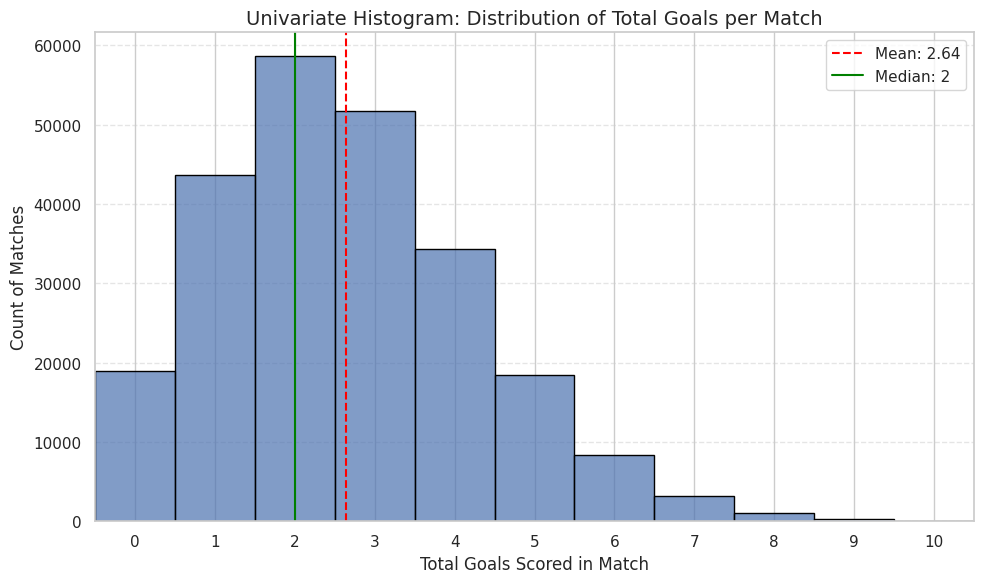

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the total goals scored in each match
clean_df['TotalGoals'] = clean_df['FTHome'] + clean_df['FTAway']

plt.figure(figsize=(10, 6))

# Plot a univariate histogram of total goals
sns.histplot(
    data=clean_df,
    x='TotalGoals',
    discrete=True,
    color='#4C72B0',
    edgecolor='black',
    alpha=0.7
)

# Calculate metrics for annotation
mean_goals = clean_df['TotalGoals'].mean()
median_goals = clean_df['TotalGoals'].median()

# Add lines for central tendencies
plt.axvline(mean_goals, color='red', linestyle='--', linewidth=1.5, label=f'Mean: {mean_goals:.2f}')
plt.axvline(median_goals, color='green', linestyle='-', linewidth=1.5, label=f'Median: {median_goals:.0f}')

plt.title('Univariate Histogram: Distribution of Total Goals per Match', fontsize=14)
plt.xlabel('Total Goals Scored in Match', fontsize=12)
plt.ylabel('Count of Matches', fontsize=12)
plt.xticks(range(int(clean_df['TotalGoals'].max()) + 1))
plt.xlim(-0.5, 10.5)  # Restrict x-axis limits to 10 goals for readability of main distribution
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

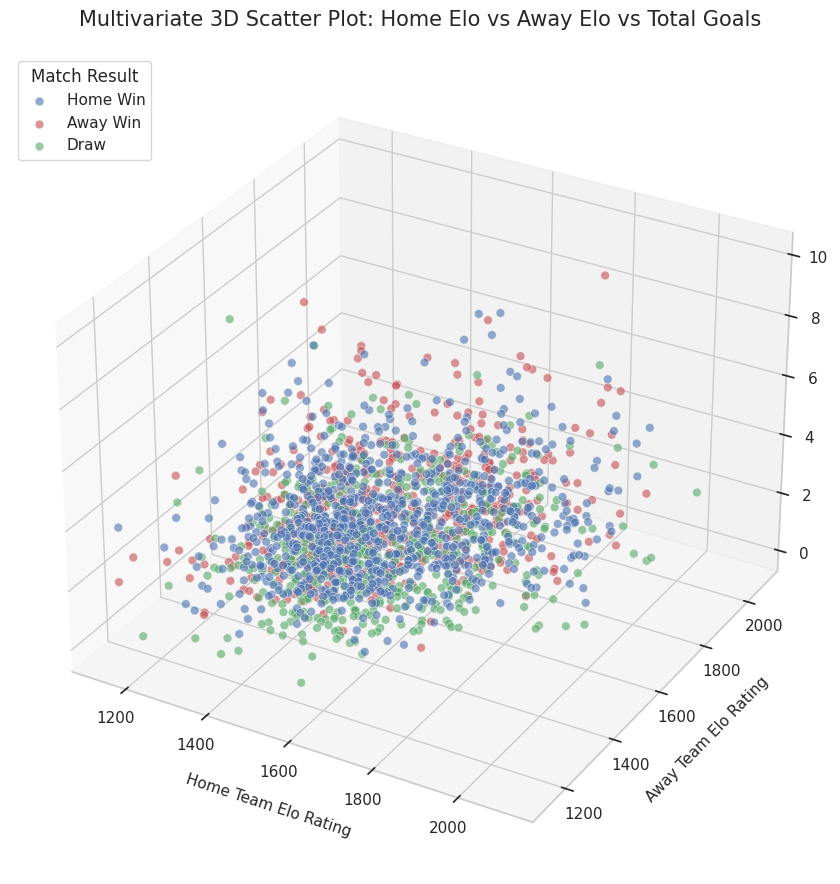

In [15]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import pandas as pd

# Drop rows where needed features are missing
plot_3d_data = clean_df.dropna(subset=['HomeElo', 'AwayElo', 'FTHome', 'FTAway', 'FTResult']).copy()
plot_3d_data['TotalGoals'] = plot_3d_data['FTHome'] + plot_3d_data['FTAway']

# Map outcomes for friendly legend labels
result_colors = {'H': '#4C72B0', 'A': '#C44E52', 'D': '#55A868'}
result_labels = {'H': 'Home Win', 'A': 'Away Win', 'D': 'Draw'}

# Subsample 2,000 matches to ensure fluid performance
sample_3d = plot_3d_data.sample(n=min(2000, len(plot_3d_data)), random_state=42)

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# Plot each outcome category separately to build a legend
for outcome, color in result_colors.items():
    subset = sample_3d[sample_3d['FTResult'] == outcome]
    ax.scatter(
        subset['HomeElo'],
        subset['AwayElo'],
        subset['TotalGoals'],
        color=color,
        label=result_labels[outcome],
        s=40,
        alpha=0.6,
        edgecolors='w',
        linewidth=0.5
    )

# Set labels and title
ax.set_title('Multivariate 3D Scatter Plot: Home Elo vs Away Elo vs Total Goals', fontsize=15, pad=20)
ax.set_xlabel('Home Team Elo Rating', fontsize=11, labelpad=10)
ax.set_ylabel('Away Team Elo Rating', fontsize=11, labelpad=10)
ax.set_zlabel('Total Goals Scored', fontsize=11, labelpad=10)

ax.legend(title='Match Result', fontsize=11, loc='upper left')
ax.grid(True)

plt.tight_layout()
plt.show()

In [17]:
import plotly.express as px
import pandas as pd

# Prepare data with a 'Year' column for temporal animation
temporal_data = clean_df.dropna(subset=['HomeElo', 'AwayElo', 'MatchDate', 'FTResult']).copy()
temporal_data['Year'] = temporal_data['MatchDate'].dt.year

# Sort chronologically to make sure the animation slider moves sequentially
temporal_data = temporal_data.sort_values('Year')

# Sample data per year using modern pandas syntax to avoid deprecation warnings
sampled_temporal = temporal_data.groupby('Year', group_keys=False).apply(
    lambda x: x.sample(n=min(150, len(x)), random_state=42),
    include_groups=False
).reset_index()

# Re-extract Year if it was removed during grouping with include_groups=False
if 'Year' not in sampled_temporal.columns and 'MatchDate' in sampled_temporal.columns:
    sampled_temporal['Year'] = sampled_temporal['MatchDate'].dt.year

# Map FTResult for user-friendly labeling
result_map = {'H': 'Home Win', 'A': 'Away Win', 'D': 'Draw'}
sampled_temporal['MatchResult'] = sampled_temporal['FTResult'].map(result_map)

# Create the animated scatter plot using Plotly Express
fig = px.scatter(
    sampled_temporal,
    x='HomeElo',
    y='AwayElo',
    animation_frame='Year',
    color='MatchResult',
    hover_name='HomeTeam',
    hover_data=['AwayTeam', 'FTHome', 'FTAway'],
    range_x=[1100, 2100],
    range_y=[1100, 2100],
    color_discrete_map={'Home Win': '#4C72B0', 'Away Win': '#C44E52', 'Draw': '#55A868'},
    title='Temporal Animated Scatter: Evolution of Team Matchups Over Time'
)

# Add a diagonal y=x line representing equal strength matchups
fig.add_shape(
    type='line',
    x0=1100, y0=1100, x1=2100, y1=2100,
    line=dict(color='Gray', dash='dash', width=1.5)
)

fig.update_layout(
    xaxis_title='Home Team Elo',
    yaxis_title='Away Team Elo',
    legend_title_text='Match Result',
    width=900,
    height=700
)

fig.show()

In [18]:
import ipywidgets as widgets
from ipywidgets import interact
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Prepare dataset with necessary columns
plot_multivariate_df = clean_df.copy()
plot_multivariate_df['TotalGoals'] = plot_multivariate_df['FTHome'] + plot_multivariate_df['FTAway']

# Define the metric options available for the y-axis
y_metric_options = {
    'Away Team Elo Rating': 'AwayElo',
    'Total Goals Scored': 'TotalGoals',
    'Home Team Shots': 'HomeShots',
    'Away Team Shots': 'AwayShots',
    'Home Team Corners': 'HomeCorners',
    'Away Team Corners': 'AwayCorners'
}

# Take a representative sample to ensure smooth visualization updates
sample_multi = plot_multivariate_df.dropna(subset=['HomeElo', 'FTResult']).sample(n=1500, random_state=42)
result_labels = {'H': 'Home Win', 'A': 'Away Win', 'D': 'Draw'}
sample_multi['MatchResult'] = sample_multi['FTResult'].map(result_labels)

@interact(Y_Metric=widgets.Dropdown(
    options=y_metric_options,
    value='AwayElo',
    description='Y-Axis Metric:'
))
def update_multivariate_scatter(Y_Metric):
    plt.figure(figsize=(11, 7))

    # Drop NaNs just for the chosen Y metric to plot cleanly
    subset = sample_multi.dropna(subset=[Y_Metric])

    if len(subset) == 0:
        plt.text(0.5, 0.5, 'No data available for this metric selection.', ha='center', va='center', fontsize=14)
        plt.show()
        return

    sns.scatterplot(
        data=subset,
        x='HomeElo',
        y=Y_Metric,
        hue='MatchResult',
        palette={'Home Win': '#4C72B0', 'Away Win': '#C44E52', 'Draw': '#55A868'},
        alpha=0.7,
        edgecolor='w',
        s=50
    )

    # Get friendly label name for title
    friendly_y_label = [name for name, val in y_metric_options.items() if val == Y_Metric][0]

    plt.title(f'Interactive Scatter Plot: Home Elo vs {friendly_y_label}', fontsize=14, pad=15)
    plt.xlabel('Home Team Elo Rating', fontsize=12)
    plt.ylabel(friendly_y_label, fontsize=12)
    plt.legend(title='Match Result', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

interactive(children=(Dropdown(description='Y-Axis Metric:', options={'Away Team Elo Rating': 'AwayElo', 'Tota…